In [1]:
import dask.dataframe as dd
from dask.distributed import Client

client = Client(n_workers=2, threads_per_worker=1, memory_limit="2GB")
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:54250,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:54262,Total threads: 1
Dashboard: http://127.0.0.1:54265/status,Memory: 1.86 GiB
Nanny: tcp://127.0.0.1:54253,


2026-10-09 23:23:55,205 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle e77010a5ee336ec7b77a0919f531ccc8 initialized by task ('shuffle-transfer-e77010a5ee336ec7b77a0919f531ccc8', 0) executed on worker tcp://127.0.0.1:54262
2026-10-09 23:23:56,065 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle e77010a5ee336ec7b77a0919f531ccc8 deactivated due to stimulus 'task-finished-1791606236.0552948'


In [2]:
columnas = {
    "SUCURSAL": "sucursal",
    "ID_POLIZA": "id_poliza",
    "TIPO DE MOVIMIENTO": "movimiento",
    "FECHA DE EMISION": "fecha_emision",
    "FECHA INICIO DE VIGENCIA": "inicio_vigencia",
    "DIAS POR DEVENGAR": "dias_por_devengar",
    "PRIMAS EMITIDAS MONEDA EQUIVALENTE": "prima_emitida",
    "PRIMAS CANCELADAS MONEDA EQUIVALENTE": "prima_cancelada",
    "RPND RETENIDA": "rpnd",
}

ddf = dd.read_csv(
    "datos_anonimizados/reserva_soat_202512_anon.txt",
    sep="~", usecols=list(columnas), dtype=str, blocksize="128MB",
).rename(columns=columnas)

print("Particiones:", ddf.npartitions)
ddf.head()

Particiones: 13


,sucursal,id_poliza,movimiento,fecha_emision,inicio_vigencia,dias_por_devengar,prima_emitida,prima_cancelada,rpnd
0,1,2c9e4025ed178857,EXPEDICION,15/11/2024,08/01/2025,8,201600.0000,0.0000,13365.2033
1,1,d720b7de93e84272,EXPEDICION,28/11/2024,06/01/2025,6,201600.0000,0.0000,10023.9024
2,1,e99bb6dfc48fce3d,EXPEDICION,02/12/2024,01/01/2025,1,424000.0000,0.0000,382.8983
3,1,0865a383a6265849,EXPEDICION,04/12/2024,02/01/2025,2,150100.0000,0.0000,3698.7865
4,1,88e4b8328fea499a,EXPEDICION,05/12/2024,19/01/2025,19,201600.0000,0.0000,31715.5579


In [3]:
for c in ["fecha_emision", "inicio_vigencia"]:
    ddf[c] = dd.to_datetime(ddf[c], format="%d/%m/%Y")
for c in ["dias_por_devengar", "prima_emitida", "prima_cancelada", "rpnd"]:
    ddf[c] = ddf[c].astype(float)

ddf["mes_emision"] = ddf["fecha_emision"].dt.strftime("%Y-%m")
ddf["dias_anticipacion"] = (ddf["inicio_vigencia"] - ddf["fecha_emision"]).dt.days

ddf.to_parquet("datos_anonimizados/reserva_parquet", write_index=False)
print("Listo")

Listo


In [4]:
ddf = dd.read_parquet("datos_anonimizados/reserva_parquet")

print("Filas:", len(ddf))
print()
print(ddf.dtypes)
print()
print("Nulos por columna:")
print(ddf.isna().sum().compute())
print()
print(ddf["movimiento"].value_counts().compute())

Filas: 3316704

sucursal                     string
id_poliza                    string
movimiento                   string
fecha_emision        datetime64[us]
inicio_vigencia      datetime64[us]
dias_por_devengar           float64
prima_emitida               float64
prima_cancelada             float64
rpnd                        float64
mes_emision                  string
dias_anticipacion             int64
dtype: object

Nulos por columna:
sucursal             0
id_poliza            0
movimiento           0
fecha_emision        0
inicio_vigencia      0
dias_por_devengar    0
prima_emitida        0
prima_cancelada      0
rpnd                 0
mes_emision          0
dias_anticipacion    0
dtype: int64

movimiento
EXPEDICION               3315192
CANCELACION DE POLIZA       1512
Name: count, dtype: int64[pyarrow]


In [5]:
import pandas as pd
pd.options.display.float_format = "{:,.0f}".format

print(ddf[["prima_emitida", "rpnd", "dias_anticipacion", "dias_por_devengar"]].describe().compute())

ddf[ddf.movimiento != "EXPEDICION"].head(10)

       prima_emitida      rpnd  dias_anticipacion  dias_por_devengar
count      3,316,704 3,316,704          3,316,704          3,316,704
mean         345,820   183,986                  3                190
std          197,738   149,456                 15                113
min                0  -750,901               -363                  0
25%          213,300    49,375                  1                 87
50%          269,000   167,138                  1                238
75%          518,100   387,323                  1                333
max        1,500,600   785,607                657                846


,sucursal,id_poliza,movimiento,fecha_emision,inicio_vigencia,dias_por_devengar,prima_emitida,prima_cancelada,rpnd,mes_emision,dias_anticipacion
1081,1,5b8edb8d32a685cc,CANCELACION DE POLIZA,2025-01-15,2025-01-30,30,0,"-833,500","-11,493",2025-01,15
1846,1,fb2157c2d522d729,CANCELACION DE POLIZA,2025-01-24,2025-01-27,27,0,"-1,061,500","-18,474",2025-01,3
6937,1,d3b112a56bd3e40a,CANCELACION DE POLIZA,2025-05-12,2025-04-16,106,0,"-839,200","-63,622",2025-05,-26
17243,1,50fdbfc07131b844,CANCELACION DE POLIZA,2025-09-16,2025-09-13,256,0,"-602,400","-282,877",2025-09,-3
20882,1,20cfea3b9cb4837a,CANCELACION DE POLIZA,2025-12-03,2025-11-29,333,0,"-213,300","-374,064",2025-12,-4
20884,1,f3a51c4407800ca6,CANCELACION DE POLIZA,2025-12-03,2025-12-01,335,0,"-387,100","-194,696",2025-12,-2
22856,3,3c22b361ec2ca44b,CANCELACION DE POLIZA,2025-01-15,2024-12-02,0,0,"-1,082,600",0,2025-01,-44
23979,3,a624880e91201614,CANCELACION DE POLIZA,2025-02-04,2025-01-25,25,0,"-618,900","-5,540",2025-02,-10
25146,3,75aad013c45d085d,CANCELACION DE POLIZA,2025-05-09,2025-04-21,51,0,"-701,300","-30,236",2025-05,-18
25292,3,cae2c510b44e4104,CANCELACION DE POLIZA,2025-05-09,2025-04-21,56,0,"-712,800","-33,542",2025-05,-18


In [6]:
por_mes = ddf[ddf.movimiento == "EXPEDICION"].groupby("mes_emision").agg(
    {"id_poliza": "count", "prima_emitida": "sum", "rpnd": "sum"}
).compute().sort_index().rename(columns={"id_poliza": "polizas"})

por_mes.tail(13)

,polizas,prima_emitida,rpnd
mes_emision,,,
2024-12,21262,"9,118,456,376","293,401,071"
2025-01,291042,"101,990,594,801","5,601,598,355"
2025-02,274980,"93,066,093,440","12,792,447,567"
2025-03,274784,"92,956,391,304","20,538,694,140"
2025-04,231121,"78,733,487,432","24,369,112,498"
2025-05,234283,"78,579,929,244","32,800,451,434"
2025-06,225040,"77,931,857,173","38,066,877,511"
2025-07,281311,"95,819,484,641","51,800,703,934"
2025-08,247170,"84,358,075,370","53,098,701,651"


In [7]:
ddf["prima_neta"] = ddf["prima_emitida"] + ddf["prima_cancelada"]

print("Prima emitida:  ", f'{ddf["prima_emitida"].sum().compute():,.0f}')
print("Prima cancelada:", f'{ddf["prima_cancelada"].sum().compute():,.0f}')
print("Prima neta:     ", f'{ddf["prima_neta"].sum().compute():,.0f}')

Prima emitida:   1,146,981,133,297
Prima cancelada: -734,539,661
Prima neta:      1,146,246,593,636


In [8]:
por_mes = ddf[ddf.movimiento == "EXPEDICION"].groupby("mes_emision").agg(
    {"id_poliza": "count", "prima_emitida": "sum", "rpnd": "sum"}
).compute().sort_index().rename(columns={"id_poliza": "polizas"})

por_mes.tail(13)

,polizas,prima_emitida,rpnd
mes_emision,,,
2024-12,21262,"9,118,456,376","293,401,071"
2025-01,291042,"101,990,594,801","5,601,598,355"
2025-02,274980,"93,066,093,440","12,792,447,567"
2025-03,274784,"92,956,391,304","20,538,694,140"
2025-04,231121,"78,733,487,432","24,369,112,498"
2025-05,234283,"78,579,929,244","32,800,451,434"
2025-06,225040,"77,931,857,173","38,066,877,511"
2025-07,281311,"95,819,484,641","51,800,703,934"
2025-08,247170,"84,358,075,370","53,098,701,651"


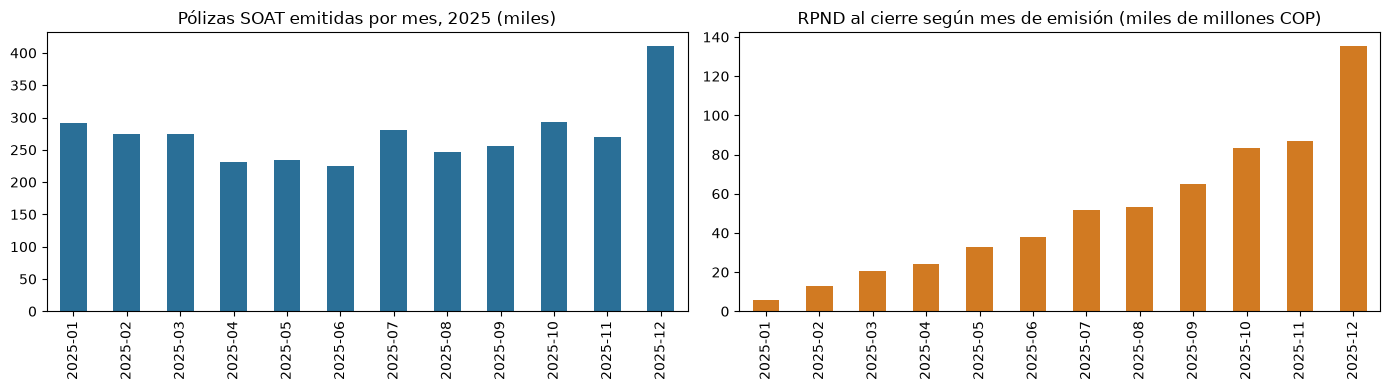

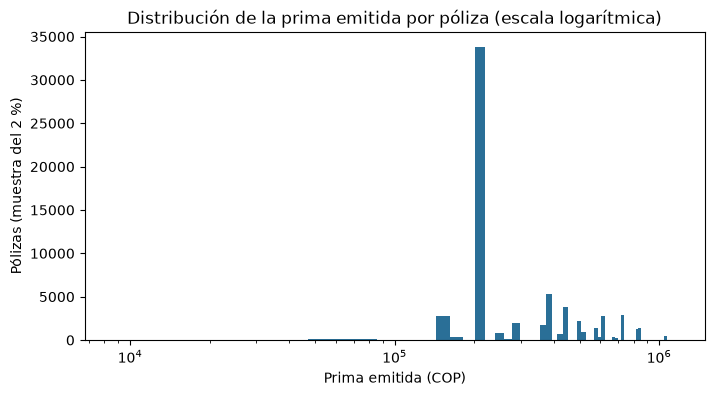

In [9]:
import matplotlib.pyplot as plt

m = por_mes.loc["2025-01":"2025-12"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(m["polizas"] / 1000).plot.bar(ax=ax[0], color="#2a6f97")
ax[0].set_title("Pólizas SOAT emitidas por mes, 2025 (miles)")
ax[0].set_xlabel("")
(m["rpnd"] / 1e9).plot.bar(ax=ax[1], color="#d17a22")
ax[1].set_title("RPND al cierre según mes de emisión (miles de millones COP)")
ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

muestra = ddf[ddf.prima_emitida > 0][["prima_emitida"]].sample(frac=0.02, random_state=1).compute()
plt.figure(figsize=(8, 4))
plt.hist(muestra["prima_emitida"], bins=60, color="#2a6f97")
plt.xscale("log")
plt.title("Distribución de la prima emitida por póliza (escala logarítmica)")
plt.xlabel("Prima emitida (COP)"); plt.ylabel("Pólizas (muestra del 2 %)")
plt.show()

In [10]:
import time

def probar(n_workers, memoria):
    c = Client(n_workers=n_workers, threads_per_worker=1, memory_limit=memoria)
    d = dd.read_csv("datos_anonimizados/reserva_soat_202512_anon.txt", sep="~",
                    usecols=["SUCURSAL", "PRIMAS EMITIDAS MONEDA EQUIVALENTE"],
                    dtype=str, blocksize="128MB")
    d["p"] = d["PRIMAS EMITIDAS MONEDA EQUIVALENTE"].astype(float)
    t = time.time()
    d.groupby("SUCURSAL")["p"].sum().compute()
    seg = round(time.time() - t, 1)
    print(f"{n_workers} workers, {memoria} por worker: {seg} segundos  |  tablero: {c.dashboard_link}")
    c.close()
    return seg

client.close()
t1 = probar(2, "2GB")
t2 = probar(4, "1GB")

2026-10-09 23:37:25,322 - distributed.client - ERROR - 
Traceback (most recent call last):
  File "c:\Users\eagom\OneDrive\Escritorio\UNIVERSIDAD DE LA SABANA\BIGDATA\TRABAJO FINAL\.venv\Lib\site-packages\distributed\utils.py", line 821, in wrapper
    return await func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\eagom\OneDrive\Escritorio\UNIVERSIDAD DE LA SABANA\BIGDATA\TRABAJO FINAL\.venv\Lib\site-packages\distributed\client.py", line 1912, in _close
    await self.cluster.close()
  File "c:\Users\eagom\OneDrive\Escritorio\UNIVERSIDAD DE LA SABANA\BIGDATA\TRABAJO FINAL\.venv\Lib\site-packages\distributed\deploy\spec.py", line 461, in _close
    await self.scheduler_comm.terminate()
  File "c:\Users\eagom\OneDrive\Escritorio\UNIVERSIDAD DE LA SABANA\BIGDATA\TRABAJO FINAL\.venv\Lib\site-packages\distributed\core.py", line 1142, in send_recv_from_rpc
    result = await send_recv(comm=comm, op=key, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

TimeoutError: timed out after 60 s.

In [1]:
import time
import dask.dataframe as dd
from dask.distributed import Client, LocalCluster

def probar(n_workers, memoria):
    cluster = LocalCluster(n_workers=n_workers, threads_per_worker=1, memory_limit=memoria)
    c = Client(cluster)
    d = dd.read_csv("datos_anonimizados/reserva_soat_202512_anon.txt", sep="~",
                    usecols=["SUCURSAL", "PRIMAS EMITIDAS MONEDA EQUIVALENTE"],
                    dtype=str, blocksize="128MB")
    d["p"] = d["PRIMAS EMITIDAS MONEDA EQUIVALENTE"].astype(float)
    t = time.time()
    d.groupby("SUCURSAL")["p"].sum().compute()
    seg = round(time.time() - t, 1)
    print(f"{n_workers} workers, {memoria} por worker: {seg} segundos")
    try:
        c.close(); cluster.close(timeout=10)
    except Exception:
        pass
    time.sleep(3)
    return seg

t1 = probar(2, "2GB")
t2 = probar(4, "1GB")
print("Diferencia:", round(t1 - t2, 1), "segundos")

2 workers, 2GB por worker: 21.0 segundos
4 workers, 1GB por worker: 13.2 segundos
Diferencia: 7.8 segundos
